In [1]:
import time
import numpy as np
from pathlib import Path
from plantdata import load_classes, read_manifest, PlantDataset
from features import image_features, save_split, GROUPS

SPLITS_DIR, CACHE_DIR = Path("splits_v2"), Path("cache_256")
CLASS_IDS, CROPS, crop_mask = load_classes(SPLITS_DIR)
manifest = read_manifest(CACHE_DIR)

f = image_features(PlantDataset(manifest, "train", CACHE_DIR, CROPS).paths[0])
print("features per image:", f.shape, "| groups:", {g: s.stop - s.start for g, s in GROUPS.items()})

for split in ["train", "val_lab", "val_wild"]:
    t0 = time.perf_counter()
    X = save_split(PlantDataset(manifest, split, CACHE_DIR, CROPS), split, workers=12)
    print(f"{split:9s} {X.shape} in {time.perf_counter() - t0:.0f} s | any NaN: {bool(np.isnan(X).any())}")

features per image: (70,) | groups: {'colour': 34, 'lbp': 28, 'glcm': 8}
train     (18475, 70) in 119 s | any NaN: False
val_lab   (3972, 70) in 29 s | any NaN: False
val_wild  (1630, 70) in 13 s | any NaN: False


In [2]:
from baseline import run_config
from features import load_split

crop_mask_np = crop_mask.numpy()
data = {s: load_split(s) for s in ["train", "val_lab", "val_wild"]}

CONFIGS = [
    # id    model            features   settings
    ("C01", "logreg",        "all",     dict(C=0.01)),
    ("C02", "logreg",        "all",     dict(C=0.1)),
    ("C03", "logreg",        "all",     dict(C=1.0)),
    ("C04", "logreg",        "all",     dict(C=10.0)),
    ("C05", "logreg",        "colour",  dict(C=1.0)),
    ("C06", "logreg",        "texture", dict(C=1.0)),
    ("C07", "logreg",        "all",     dict(C=1.0, class_weight="balanced")),
    ("C08", "linear_svm",    "all",     dict(C=0.1)),
    ("C09", "linear_svm",    "all",     dict(C=1.0)),
    ("C10", "rbf_svm",       "all",     dict(C=1.0)),
    ("C11", "rbf_svm",       "all",     dict(C=10.0)),
    ("C12", "rbf_svm",       "all",     dict(C=100.0)),
    ("C13", "random_forest", "all",     dict(min_samples_leaf=1)),
    ("C14", "random_forest", "all",     dict(min_samples_leaf=5)),
    ("C15", "random_forest", "all",     dict(max_depth=12)),
    ("C16", "random_forest", "colour",  dict(min_samples_leaf=1)),
    ("C17", "random_forest", "texture", dict(min_samples_leaf=1)),
    ("C18", "grad_boost",    "all",     dict(learning_rate=0.1)),
    ("C19", "grad_boost",    "all",     dict(learning_rate=0.03)),
    ("C20", "grad_boost",    "all",     dict(learning_rate=0.1, l2_regularization=1.0)),
]
for config_id, kind, feature_set, params in CONFIGS:
    run_config(config_id, kind, feature_set, params, data, CLASS_IDS, crop_mask_np)

C01: logreg        all     {'C': 0.01}                            | fit    0.8 s | val_lab F1-16 0.866 | val_wild F1-16 0.289
C02: logreg        all     {'C': 0.1}                             | fit    0.9 s | val_lab F1-16 0.895 | val_wild F1-16 0.309
C03: logreg        all     {'C': 1.0}                             | fit    1.1 s | val_lab F1-16 0.912 | val_wild F1-16 0.313
C04: logreg        all     {'C': 10.0}                            | fit    2.5 s | val_lab F1-16 0.914 | val_wild F1-16 0.322
C05: logreg        colour  {'C': 1.0}                             | fit    0.9 s | val_lab F1-16 0.849 | val_wild F1-16 0.315
C06: logreg        texture {'C': 1.0}                             | fit    1.9 s | val_lab F1-16 0.739 | val_wild F1-16 0.275
C07: logreg        all     {'C': 1.0, 'class_weight': 'balanced'} | fit    1.1 s | val_lab F1-16 0.904 | val_wild F1-16 0.311
C08: linear_svm    all     {'C': 0.1}                             | fit    2.2 s | val_lab F1-16 0.894 | val_wild F1-1

In [3]:
EXTRA = [
    ("C21", "logreg", "all",    dict(C=100.0)),
    ("C22", "logreg", "colour", dict(C=10.0)),
]
for config_id, kind, feature_set, params in EXTRA:
    run_config(config_id, kind, feature_set, params, data, CLASS_IDS, crop_mask_np)

C21: logreg        all     {'C': 100.0}                           | fit    3.9 s | val_lab F1-16 0.916 | val_wild F1-16 0.318
C22: logreg        colour  {'C': 10.0}                            | fit    1.5 s | val_lab F1-16 0.851 | val_wild F1-16 0.315


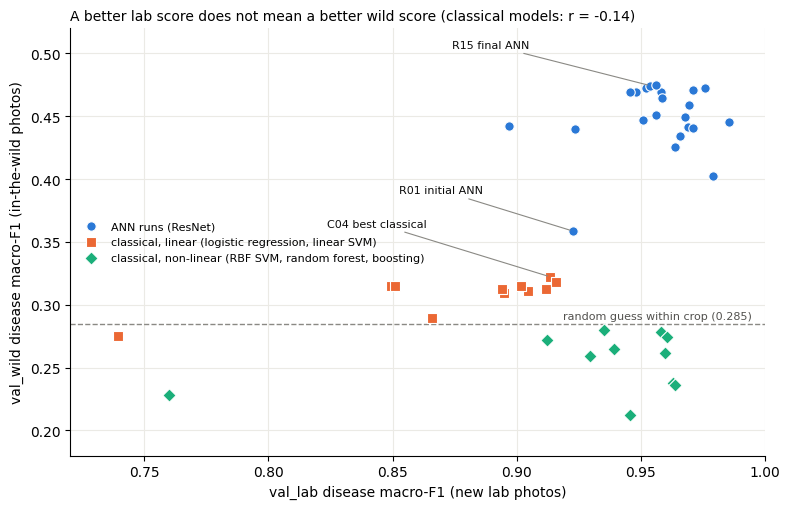

In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

ann = pd.read_csv("results/runs_summary.csv")
ann = ann[ann["run_id"].str.match(r"R\d+$")]
base = pd.read_csv("results/baseline_summary.csv")
linear = base["kind"].isin(["logreg", "linear_svm"])

groups = [
    ("ANN runs (ResNet)", ann["val_lab_f1_16"], ann["val_wild_f1_16"], "#2a78d6", "o"),
    ("classical, linear (logistic regression, linear SVM)", base.loc[linear, "val_lab_macro_f1_16_disease"],
     base.loc[linear, "val_wild_macro_f1_16_disease"], "#eb6834", "s"),
    ("classical, non-linear (RBF SVM, random forest, boosting)", base.loc[~linear, "val_lab_macro_f1_16_disease"],
     base.loc[~linear, "val_wild_macro_f1_16_disease"], "#1baf7a", "D"),
]
r = np.corrcoef(base["val_lab_macro_f1_16_disease"], base["val_wild_macro_f1_16_disease"])[0, 1]

fig, ax = plt.subplots(figsize=(8, 5.2))
for label, x, y, colour, marker in groups:
    ax.scatter(x, y, s=46, color=colour, marker=marker, edgecolor="white", linewidth=0.8, label=label, zorder=3)
ax.axhline(0.285, color="#8a8984", lw=1, ls="--", zorder=1)
ax.text(0.995, 0.287, "random guess within crop (0.285)", color="#52514e", fontsize=8, ha="right", va="bottom")

def mark(x, y, text, dx, dy):
    ax.annotate(text, (x, y), xytext=(x + dx, y + dy), fontsize=8, color="#0b0b0b",
                arrowprops=dict(arrowstyle="-", color="#8a8984", lw=0.8))
a, b = ann.set_index("run_id"), base.set_index("config_id")
mark(a.at["R01", "val_lab_f1_16"], a.at["R01", "val_wild_f1_16"], "R01 initial ANN", -0.07, 0.03)
mark(a.at["R15", "val_lab_f1_16"], a.at["R15", "val_wild_f1_16"], "R15 final ANN", -0.08, 0.03)
best = b["val_wild_macro_f1_16_disease"].idxmax()
mark(b.at[best, "val_lab_macro_f1_16_disease"], b.at[best, "val_wild_macro_f1_16_disease"],
     f"{best} best classical", -0.09, 0.04)

ax.set_xlim(0.72, 1.0)
ax.set_ylim(0.18, 0.52)
ax.set_xlabel("val_lab disease macro-F1 (new lab photos)")
ax.set_ylabel("val_wild disease macro-F1 (in-the-wild photos)")
ax.set_title(f"A better lab score does not mean a better wild score (classical models: r = {r:.2f})",
             fontsize=10, loc="left")
ax.grid(color="#ebeae5", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="center left")
fig.tight_layout()
fig.savefig("figures/q3_lab_vs_wild.png", dpi=200)
plt.show()

In [6]:
import time, joblib, torch
import numpy as np, pandas as pd
from PIL import Image
from baseline import masked_predict
from plantdata import eval_transform
from plantmodel import CropMaskedResNet

val_wild = PlantDataset(manifest, "val_wild", CACHE_DIR, CROPS)
sample = list(range(0, len(val_wild), max(1, len(val_wild) // 100)))[:100]     # 100 images spread over the split

def time_per_image(predict_one, warmup=5):
    for i in sample[:warmup]:
        predict_one(i)
    times = []
    for i in sample:
        t0 = time.perf_counter()
        predict_one(i)
        times.append(time.perf_counter() - t0)
    return 1000 * float(np.median(times))

clf = joblib.load("checkpoints/C04.joblib")
def classical_one(i):
    f = image_features(val_wild.paths[i])[None]
    return masked_predict(clf, f, val_wild.crop_idx[i:i + 1].numpy(), crop_mask_np)

tf = eval_transform()
def ann_one_factory(model, device):
    @torch.no_grad()
    def ann_one(i):
        x = tf(Image.open(val_wild.paths[i]).convert("RGB"))[None].to(device)
        logits = model(x, val_wild.crop_idx[i:i + 1].to(device))
        return logits.argmax(1).item()            # .item() waits for the GPU to finish
    return ann_one

latency = {"C04 classical (CPU)": time_per_image(classical_one)}
for run_id in ["R01", "R15"]:
    ck = torch.load(f"checkpoints/{run_id}.pt", map_location="cpu", weights_only=False)
    for device in ["cuda", "cpu"]:
        model = CropMaskedResNet(ck["config"]["depth"], crop_mask, pretrained=False)
        model.load_state_dict(ck["state_dict"])
        model.to(device).eval()
        latency[f"{run_id} ANN ({device.upper()})"] = time_per_image(ann_one_factory(model, device))
latency = pd.Series(latency, name="ms per image (median, batch of 1)").round(1)
latency.to_csv("results/latency.csv")
latency

C04 classical (CPU)    15.9
R01 ANN (CUDA)          4.8
R01 ANN (CPU)          15.6
R15 ANN (CUDA)          4.1
R15 ANN (CPU)          15.4
Name: ms per image (median, batch of 1), dtype: float64

In [7]:
bench = pd.read_csv("results/benchmarks.csv").set_index(["benchmark", "split"])
runs = pd.read_csv("results/runs_summary.csv").set_index("run_id")
base = pd.read_csv("results/baseline_summary.csv").set_index("config_id")
lat = pd.read_csv("results/latency.csv", index_col=0).iloc[:, 0]

def ms(key):
    return f"{lat[key]:.1f}" if key in lat else "–"

final = runs.loc[["R15", "R21", "R22"]]
def mean_sd(col):
    return f"{final[col].mean():.3f} ± {final[col].std():.3f}"

table = pd.DataFrame([
    {"model": "Trivial benchmark: random guess within crop",
     "val_lab F1-16": f"{bench.loc[('random within crop', 'val_lab'), 'macro_f1_16_disease']:.3f}",
     "val_wild F1-16 (primary)": f"{bench.loc[('random within crop', 'val_wild'), 'macro_f1_16_disease']:.3f}",
     "val_wild F1-20": f"{bench.loc[('random within crop', 'val_wild'), 'macro_f1_20']:.3f}",
     "val_wild late-blight recall": "–", "training": "none", "latency ms (GPU / CPU)": "–"},
    {"model": "Classical baseline C04: logistic regression (C=10), 70 colour+texture features",
     "val_lab F1-16": f"{base.at['C04', 'val_lab_macro_f1_16_disease']:.3f}",
     "val_wild F1-16 (primary)": f"{base.at['C04', 'val_wild_macro_f1_16_disease']:.3f}",
     "val_wild F1-20": f"{base.at['C04', 'val_wild_macro_f1_20']:.3f}",
     "val_wild late-blight recall": f"{base.at['C04', 'val_wild_late_blight_recall']:.3f}",
     "training": f"{60 * base.at['C04', 'fit_minutes']:.0f} s fit (+ feature extraction)",
     "latency ms (GPU / CPU)": f"– / {ms('C04 classical (CPU)')}"},
    {"model": "Initial ANN R01: ResNet-18, frozen backbone (head only)",
     "val_lab F1-16": f"{runs.at['R01', 'val_lab_f1_16']:.3f}",
     "val_wild F1-16 (primary)": f"{runs.at['R01', 'val_wild_f1_16']:.3f}",
     "val_wild F1-20": f"{runs.at['R01', 'val_wild_f1_20']:.3f}",
     "val_wild late-blight recall": f"{runs.at['R01', 'val_wild_late_blight_recall']:.3f}",
     "training": f"{runs.at['R01', 'train_minutes']:.1f} min",
     "latency ms (GPU / CPU)": f"{ms('R01 ANN (CUDA)')} / {ms('R01 ANN (CPU)')}"},
    {"model": "Final ANN: ResNet-18, full fine-tuning (mean ± sd, 3 seeds; deployed = R15)",
     "val_lab F1-16": mean_sd("val_lab_f1_16"),
     "val_wild F1-16 (primary)": mean_sd("val_wild_f1_16"),
     "val_wild F1-20": mean_sd("val_wild_f1_20"),
     "val_wild late-blight recall": mean_sd("val_wild_late_blight_recall"),
     "training": f"{final['train_minutes'].mean():.1f} min per run",
     "latency ms (GPU / CPU)": f"{ms('R15 ANN (CUDA)')} / {ms('R15 ANN (CPU)')}"},
]).set_index("model")
table.to_csv("results/q3a_comparison_validation.csv")
table

,val_lab F1-16,val_wild F1-16 (primary),val_wild F1-20,val_wild late-blight recall,training,latency ms (GPU / CPU)
model,,,,,,
Trivial benchmark: random guess within crop,0.265,0.285,0.295,–,none,–
"Classical baseline C04: logistic regression (C=10), 70 colour+texture features",0.914,0.322,0.315,0.339,3 s fit (+ feature extraction),– / 15.9
"Initial ANN R01: ResNet-18, frozen backbone (head only)",0.923,0.359,0.382,0.829,3.2 min,4.8 / 15.6
"Final ANN: ResNet-18, full fine-tuning (mean ± sd, 3 seeds; deployed = R15)",0.957 ± 0.013,0.471 ± 0.003,0.484 ± 0.005,0.741 ± 0.054,5.3 min per run,4.1 / 15.4
